In [1]:
import pandas as pd

vendas = pd.read_csv('data/train.csv', parse_dates=['Date'], low_memory=False)
lojas = pd.read_csv('data/store.csv')

In [2]:
df = vendas.merge(lojas, on='Store', how='left')

print(df.shape)
df.head()

(1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [3]:
df.info()
df['Store'].nunique()
df['Date'].min(), df['Date'].max()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[ns]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  object        
 10  Assortment                 1017209 non-null  object        
 11  CompetitionDistance        1014567 no

(Timestamp('2013-01-01 00:00:00'), Timestamp('2015-07-31 00:00:00'))

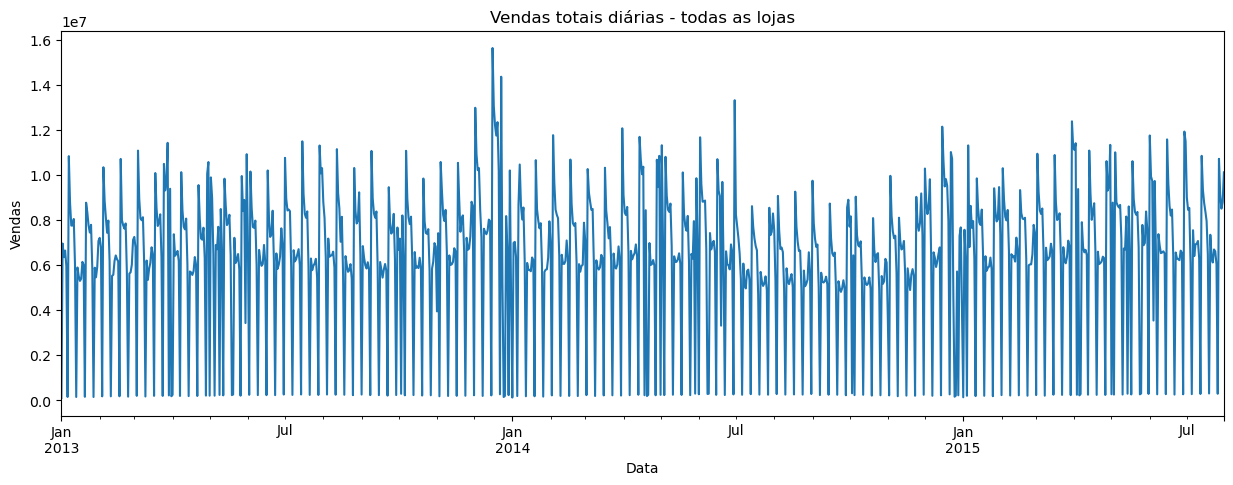

In [4]:
import matplotlib.pyplot as plt

vendas_diarias = df.groupby('Date')['Sales'].sum()

plt.figure(figsize=(15, 5))
vendas_diarias.plot()
plt.title('Vendas totais diárias - todas as lojas')
plt.xlabel('Data')
plt.ylabel('Vendas')
plt.show()

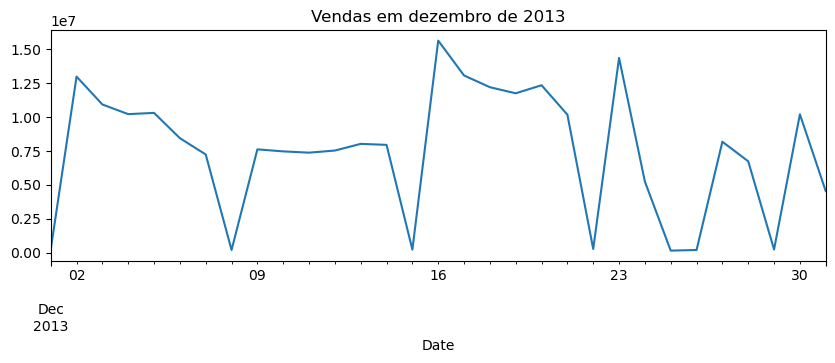

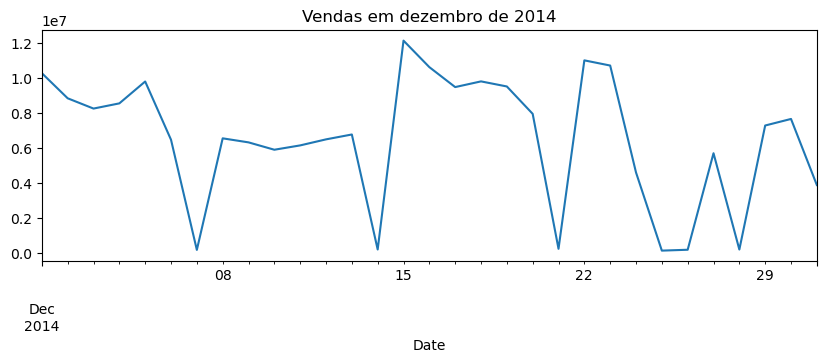

In [5]:
# olhando só dezembro de cada ano, lado a lado
for ano in [2013, 2014]:
    dez = vendas_diarias[f'{ano}-12-01':f'{ano}-12-31']
    plt.figure(figsize=(10, 3))
    dez.plot()
    plt.title(f'Vendas em dezembro de {ano}')
    plt.show()

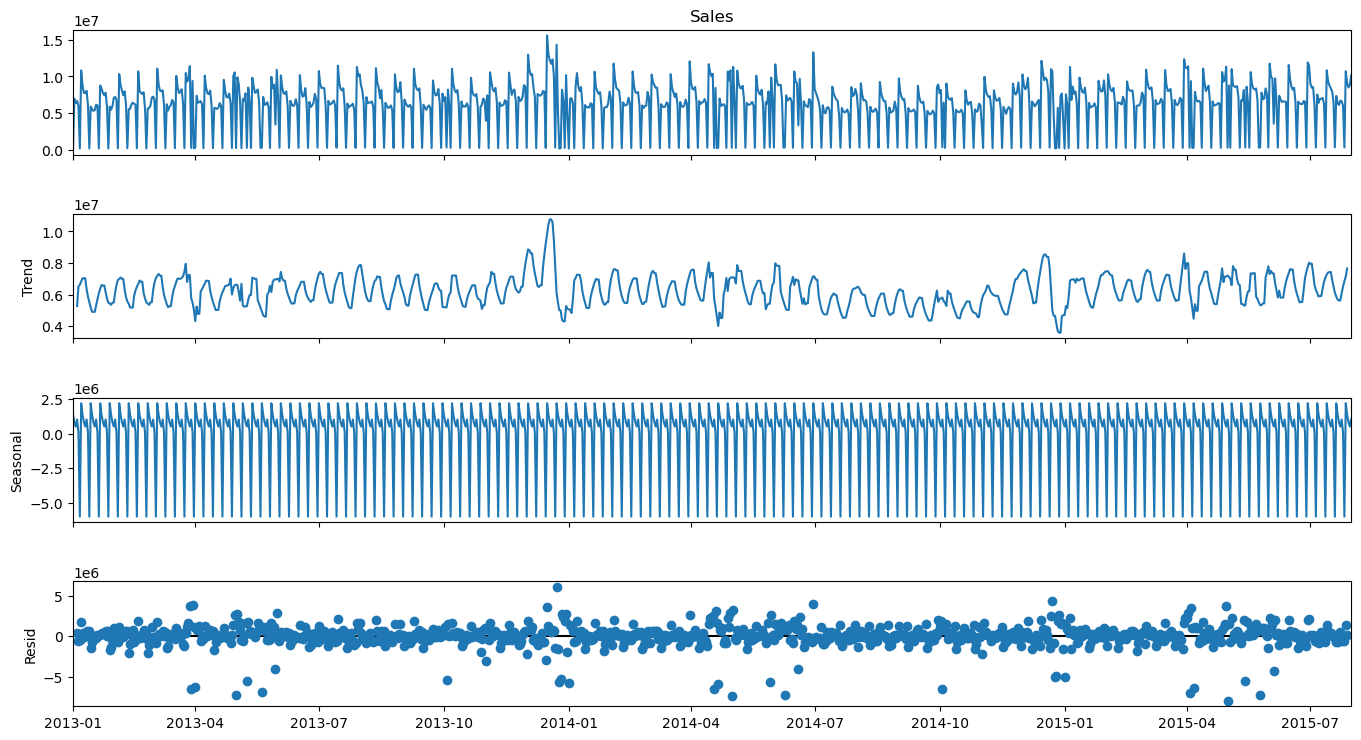

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

vendas_diarias = vendas_diarias.asfreq('D', fill_value=0)

resultado = seasonal_decompose(vendas_diarias, model='additive', period=7)

resultado.plot()
plt.gcf().set_size_inches(15, 8)
plt.show()

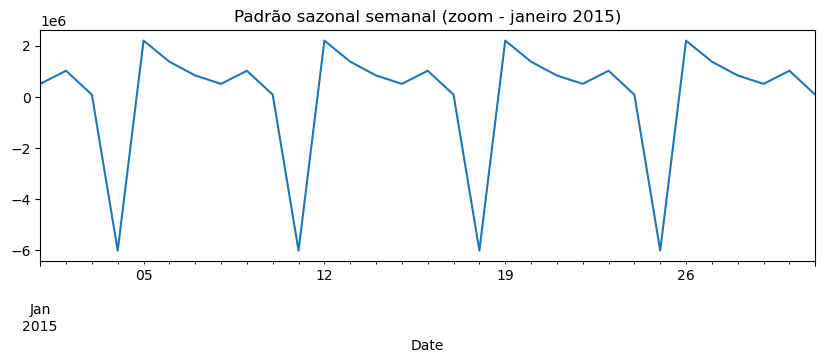

In [7]:
resultado.seasonal['2015-01-01':'2015-01-31'].plot(figsize=(10,3))
plt.title('Padrão sazonal semanal (zoom - janeiro 2015)')
plt.show()

C:\Users\Usuário\AppData\Local\Temp\ipykernel_10732\2346292285.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  vendas_mensais = vendas_diarias.resample('M').sum()


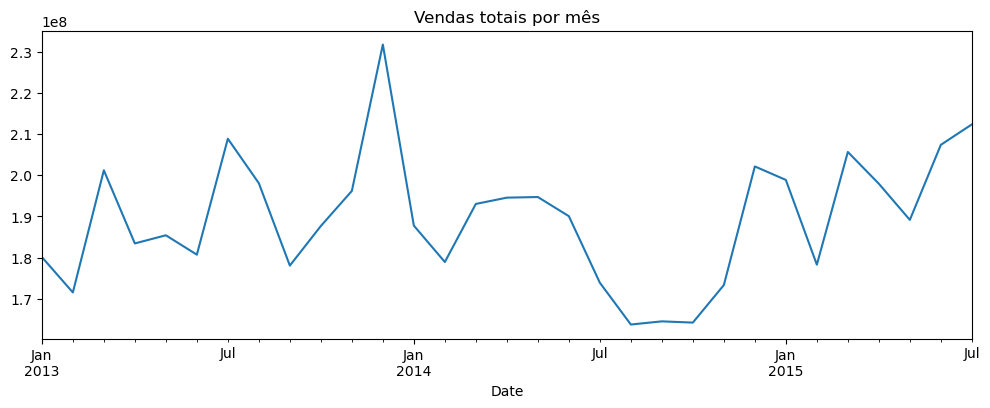

In [8]:
vendas_mensais = vendas_diarias.resample('M').sum()

plt.figure(figsize=(12,4))
vendas_mensais.plot()
plt.title('Vendas totais por mês')
plt.show()

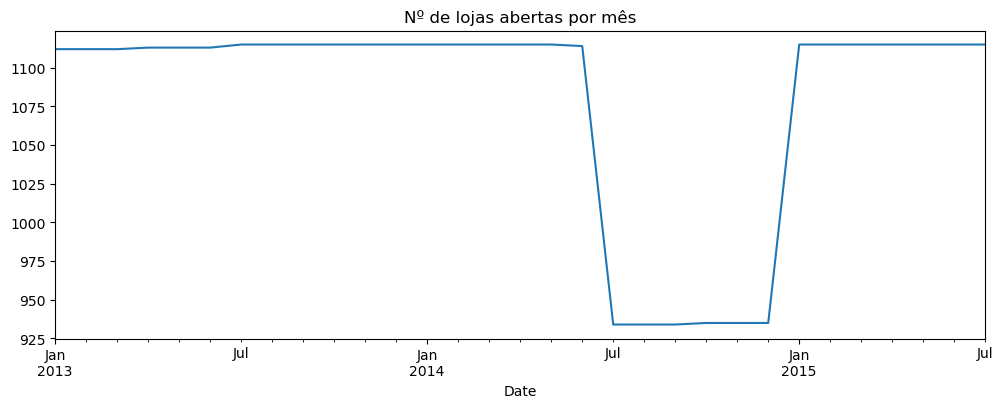

In [9]:
# contando quantas lojas estavam com Open=1 em cada mês
lojas_abertas_mes = df[df['Open'] == 1].groupby(df['Date'].dt.to_period('M'))['Store'].nunique()

plt.figure(figsize=(12,4))
lojas_abertas_mes.plot()
plt.title('Nº de lojas abertas por mês')
plt.show()

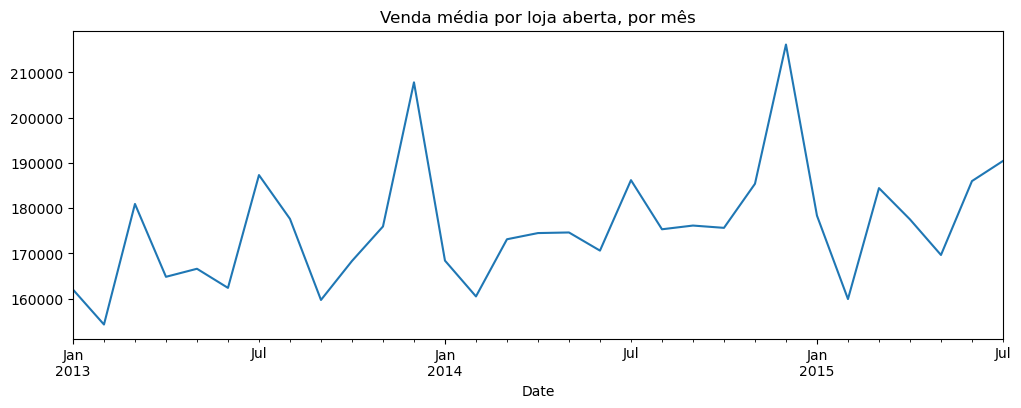

In [10]:
vendas_por_loja_aberta = df[df['Open']==1].groupby(df['Date'].dt.to_period('M')).apply(
    lambda x: x['Sales'].sum() / x['Store'].nunique()
)

plt.figure(figsize=(12,4))
vendas_por_loja_aberta.plot()
plt.title('Venda média por loja aberta, por mês')
plt.show()

In [11]:
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(df['CompetitionDistance'].median())

In [12]:
df['TemConcorrenteRegistrado'] = df['CompetitionOpenSinceMonth'].notna().astype(int)

df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0)

In [13]:
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)
df['PromoInterval'] = df['PromoInterval'].fillna('Nenhum')

In [14]:
df = df[df['Open'] == 1].copy()

In [15]:
df.isnull().sum()

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
TemConcorrenteRegistrado     0
dtype: int64

In [16]:
df['Ano'] = df['Date'].dt.year
df['Mes'] = df['Date'].dt.month
df['Dia'] = df['Date'].dt.day
df['DiaDoAno'] = df['Date'].dt.dayofyear
df['Semana'] = df['Date'].dt.isocalendar().week

In [17]:

df = df.sort_values(['Store', 'Date'])

df['Vendas_Lag7'] = df.groupby('Store')['Sales'].shift(7)
df['Vendas_Lag14'] = df.groupby('Store')['Sales'].shift(14)

In [18]:
df['MediaMovel_7d'] = df.groupby('Store')['Sales'].transform(lambda x: x.rolling(7, min_periods=1).mean())
df['MediaMovel_30d'] = df.groupby('Store')['Sales'].transform(lambda x: x.rolling(30, min_periods=1).mean())

In [19]:
df[['Vendas_Lag7', 'Vendas_Lag14', 'MediaMovel_7d', 'MediaMovel_30d']].isnull().sum()

Vendas_Lag7        7805
Vendas_Lag14      15610
MediaMovel_7d         0
MediaMovel_30d        0
dtype: int64

In [20]:
df = df.dropna(subset=['Vendas_Lag7', 'Vendas_Lag14'])

In [21]:
df.shape

(828782, 28)

In [22]:

data_corte = df['Date'].max() - pd.Timedelta(weeks=6)

treino = df[df['Date'] <= data_corte]
teste = df[df['Date'] > data_corte]

print(treino['Date'].min(), treino['Date'].max())
print(teste['Date'].min(), teste['Date'].max())
print(treino.shape, teste.shape)

2013-01-15 00:00:00 2015-06-19 00:00:00
2015-06-20 00:00:00 2015-07-31 00:00:00
(788500, 28) (40282, 28)


In [23]:
# colunas que NÃO devem entrar como feature
colunas_remover = ['Sales', 'Date', 'Customers']

X_treino = treino.drop(columns=colunas_remover)
y_treino = treino['Sales']

X_teste = teste.drop(columns=colunas_remover)
y_teste = teste['Sales']

In [24]:
X_treino.dtypes[X_treino.dtypes == 'object']

StateHoliday     object
StoreType        object
Assortment       object
PromoInterval    object
dtype: object

In [25]:
colunas_categoricas = ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']

for col in colunas_categoricas:
    X_treino[col] = X_treino[col].astype('category')
    X_teste[col] = X_teste[col].astype('category')

In [ ]:
for col in colunas_categoricas:
    categorias = df[col].astype('category').cat.categories
    X_treino[col] = pd.Categorical(X_treino[col], categories=categorias)
    X_teste[col] = pd.Categorical(X_teste[col], categories=categorias)

In [27]:
import lightgbm as lgb

modelo = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42
)

modelo.fit(
    X_treino, y_treino,
    categorical_feature=colunas_categoricas
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.112639 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1987
[LightGBM] [Info] Number of data points in the train set: 788500, number of used features: 24
[LightGBM] [Info] Start training from score 6967.608009


LGBMRegressor(learning_rate=0.05, n_estimators=500, random_state=42)

In [28]:
previsoes = modelo.predict(X_teste)

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_teste, previsoes)
rmse = np.sqrt(mean_squared_error(y_teste, previsoes))
mape = np.mean(np.abs((y_teste - previsoes) / y_teste)) * 100

print(f'MAE:  {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAPE: {mape:.2f}%')

MAE:  620.48
RMSE: 880.48
MAPE: 9.57%


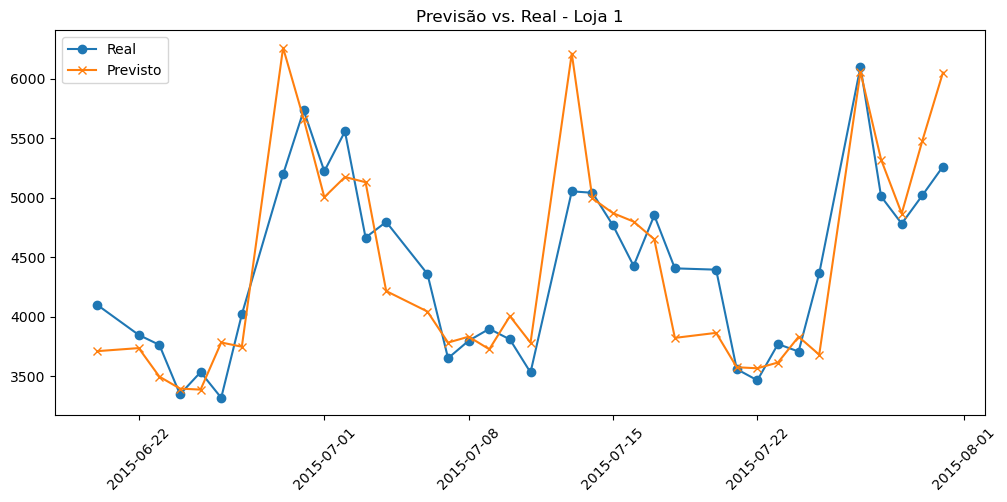

In [30]:
loja_id = 1

teste_loja = teste[teste['Store'] == loja_id].copy()
teste_loja['Previsao'] = modelo.predict(X_teste[X_teste.index.isin(teste_loja.index)])

plt.figure(figsize=(12,5))
plt.plot(teste_loja['Date'], teste_loja['Sales'], label='Real', marker='o')
plt.plot(teste_loja['Date'], teste_loja['Previsao'], label='Previsto', marker='x')
plt.legend()
plt.title(f'Previsão vs. Real - Loja {loja_id}')
plt.xticks(rotation=45)
plt.show()

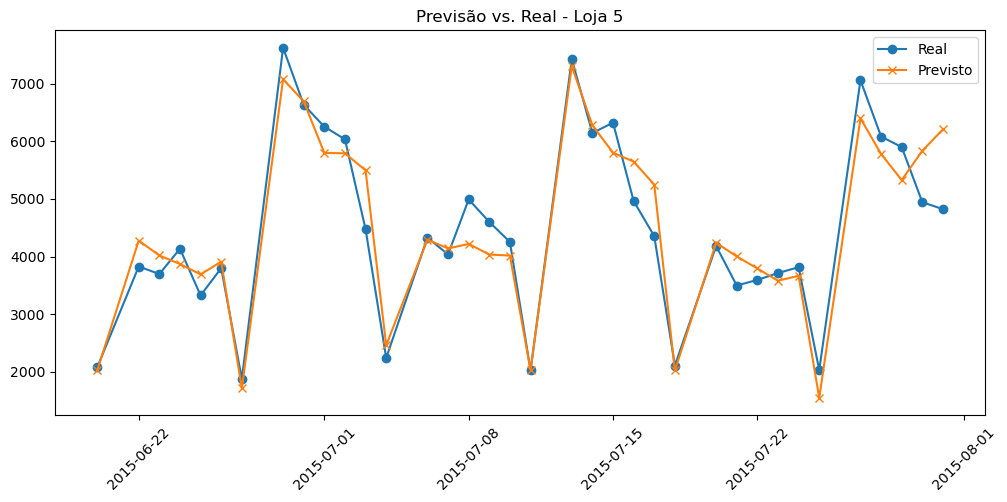

In [31]:
loja_id = 5   

teste_loja = teste[teste['Store'] == loja_id].copy()
teste_loja['Previsao'] = modelo.predict(X_teste[X_teste.index.isin(teste_loja.index)])

plt.figure(figsize=(12,5))
plt.plot(teste_loja['Date'], teste_loja['Sales'], label='Real', marker='o')
plt.plot(teste_loja['Date'], teste_loja['Previsao'], label='Previsto', marker='x')
plt.legend()
plt.title(f'Previsão vs. Real - Loja {loja_id}')
plt.xticks(rotation=45)
plt.show()

In [32]:
importancias = pd.DataFrame({
    'Feature': X_treino.columns,
    'Importancia': modelo.feature_importances_
}).sort_values('Importancia', ascending=False)

print(importancias.head(15))

                      Feature  Importancia
1                   DayOfWeek         2092
19                   DiaDoAno         1812
18                        Dia         1567
23              MediaMovel_7d         1288
8         CompetitionDistance         1074
24             MediaMovel_30d          974
21                Vendas_Lag7          821
3                       Promo          704
6                   StoreType          656
0                       Store          641
22               Vendas_Lag14          535
16                        Ano          373
10   CompetitionOpenSinceYear          326
12            Promo2SinceWeek          317
9   CompetitionOpenSinceMonth          269


In [33]:
loja_id = 1

serie_loja = df[df['Store'] == loja_id].set_index('Date')['Sales']
serie_loja = serie_loja.asfreq('D')  # garantindo frequência diária no índice

serie_treino = serie_loja[serie_loja.index <= data_corte]
serie_teste = serie_loja[serie_loja.index > data_corte]

In [34]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

modelo_sarima = SARIMAX(
    serie_treino,
    order=(1, 1, 1),          
    seasonal_order=(1, 1, 1, 7),  
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado_sarima = modelo_sarima.fit(disp=False)
print(resultado_sarima.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             Sales   No. Observations:                  883
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -5715.361
Date:                           Tue, 29 Sep 2026   AIC                          11440.722
Time:                                   18:12:10   BIC                          11464.541
Sample:                               01-18-2013   HQIC                         11449.838
                                    - 06-19-2015                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7481      0.022     34.585      0.000       0.706       0.790
ma.L1         -0.9854      0.006   -171.508

In [35]:
serie_teste

Date
2015-06-20    4097.0
2015-06-21       NaN
2015-06-22    3846.0
2015-06-23    3762.0
2015-06-24    3346.0
2015-06-25    3533.0
2015-06-26    3317.0
2015-06-27    4019.0
2015-06-28       NaN
2015-06-29    5197.0
2015-06-30    5735.0
2015-07-01    5223.0
2015-07-02    5558.0
2015-07-03    4665.0
2015-07-04    4797.0
2015-07-05       NaN
2015-07-06    4359.0
2015-07-07    3650.0
2015-07-08    3797.0
2015-07-09    3897.0
2015-07-10    3808.0
2015-07-11    3530.0
2015-07-12       NaN
2015-07-13    5054.0
2015-07-14    5042.0
2015-07-15    4767.0
2015-07-16    4427.0
2015-07-17    4852.0
2015-07-18    4406.0
2015-07-19       NaN
2015-07-20    4395.0
2015-07-21    3558.0
2015-07-22    3464.0
2015-07-23    3769.0
2015-07-24    3706.0
2015-07-25    4364.0
2015-07-26       NaN
2015-07-27    6102.0
2015-07-28    5011.0
2015-07-29    4782.0
2015-07-30    5020.0
2015-07-31    5263.0
Freq: D, Name: Sales, dtype: float64

In [ ]:
dias_fechados_teste = serie_teste[serie_teste.isna()].index
print(dias_fechados_teste)

previsoes_sarima = resultado_sarima.get_forecast(steps=len(serie_teste))
previsoes_sarima_valores = previsoes_sarima.predicted_mean

# removendo esses dias tanto do real quanto da previsão, pra manter a comparação justa
serie_teste_limpa = serie_teste.drop(dias_fechados_teste)
previsoes_sarima_limpas = previsoes_sarima_valores.drop(dias_fechados_teste)

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_sarima = mean_absolute_error(serie_teste_limpa, previsoes_sarima_limpas)
rmse_sarima = np.sqrt(mean_squared_error(serie_teste_limpa, previsoes_sarima_limpas))
mape_sarima = np.mean(np.abs((serie_teste_limpa - previsoes_sarima_limpas) / serie_teste_limpa)) * 100

print(f'SARIMA - MAE:  {mae_sarima:.2f}')
print(f'SARIMA - RMSE: {rmse_sarima:.2f}')
print(f'SARIMA - MAPE: {mape_sarima:.2f}%')

DatetimeIndex(['2015-06-21', '2015-06-28', '2015-07-05', '2015-07-12',
               '2015-07-19', '2015-07-26'],
              dtype='datetime64[ns]', name='Date', freq=None)
SARIMA - MAE:  641.82
SARIMA - RMSE: 726.30
SARIMA - MAPE: 15.25%


In [37]:
import pandas as pd
pd.Series(dias_fechados_teste).dt.day_name()

0    Sunday
1    Sunday
2    Sunday
3    Sunday
4    Sunday
5    Sunday
Name: Date, dtype: object

In [38]:
mask_loja1 = X_teste['Store'] == 1

mae_lgbm_loja1 = mean_absolute_error(y_teste[mask_loja1], previsoes[mask_loja1])
rmse_lgbm_loja1 = np.sqrt(mean_squared_error(y_teste[mask_loja1], previsoes[mask_loja1]))
mape_lgbm_loja1 = np.mean(np.abs((y_teste[mask_loja1] - previsoes[mask_loja1]) / y_teste[mask_loja1])) * 100

print(f'LightGBM (Loja 1) - MAE:  {mae_lgbm_loja1:.2f}')
print(f'LightGBM (Loja 1) - RMSE: {rmse_lgbm_loja1:.2f}')
print(f'LightGBM (Loja 1) - MAPE: {mape_lgbm_loja1:.2f}%')

LightGBM (Loja 1) - MAE:  315.44
LightGBM (Loja 1) - RMSE: 418.61
LightGBM (Loja 1) - MAPE: 7.02%


In [ ]:
teste_resultado = teste[['Store', 'Date', 'Sales']].copy()
teste_resultado['Previsao'] = previsoes 

teste_resultado.to_csv('previsoes_teste.csv', index=False)